# Examen Parcial 2026-II — Pregunta 2
## Mapeo de inundaciones con radar Sentinel-1 mediante U-Net (Sen1Floods11)

**Curso:** Redes Neuronales y Aprendizaje Profundo — UNI FIIS · **Profesor:** Ph.D. Aldo Camargo  
**Sección:** C · **Grupo:** `04` · **Fecha de entrega:** 30 de octubre de 2026

Integrantes:
Anllelo Paolito Carreazo Yrizales (líder), Salvador Lincoln Cabrera Taco, Pedro Alexander Marquez Lamadrid, Yda Ramirez Rojas, Mijael Aguirre Zegarra

> Completar la tabla y la variable `INTEGRANTES` de la celda de configuración antes de entregar.

### Mapa de entregables → secciones del cuaderno

| Entregable del enunciado | Sección |
|---|---|
| 1. U-Net propia en PyTorch con entrada VV/VH | §3 |
| 2. Ablación: (a) dorado vs. dorado+débil, (b) función de pérdida | §5 |
| 3. Evaluación en distribución: IoU, F1, precisión, recall, matriz de confusión | §6 |
| 4. Generalización geográfica (Bolivia), brecha e hipótesis | §7 |
| 5. Fallos característicos del SAR con ejemplos visuales | §8 |
| 6. Bono: fusión SAR + Sentinel-2 | §9 |

### Cómo ejecutarlo de extremo a extremo
- **Colab:** Entorno de ejecución → GPU (T4 o superior) → Ejecutar todo.
- **Local:** `jupyter nbconvert --to notebook --execute pregunta2_unet_sen1floods11.ipynb --output ejecutado.ipynb` (ver `README.md`).

Todas las cifras del informe deben salir de este cuaderno (carpeta `outputs/`). No hay datos sintéticos: se descarga Sen1Floods11 desde su bucket público.

### 1. Configuración

In [6]:
import os, sys, json, time, random, math, copy, subprocess, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

try:
    import rasterio
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "rasterio"])
    import rasterio

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore", category=UserWarning)

# ------------------------- DATOS DEL GRUPO -------------------------
INTEGRANTES = ["Anllelo Paolito Carreazo Yrizales (líder), Salvador Lincoln Cabrera Taco, Pedro Alexander Marquez Lamadrid, Yda Ramirez Rojas, Mijael Aguirre Zegarra"

]
GRUPO, SECCION = "04", "C"

# ------------------------- PRESUPUESTO DE CÓMPUTO -------------------------
# "quick": corrida reducida (pensada para terminar en una sesión corta de Colab).
# "full" : más iteraciones y más chips débiles (resultados más estables).
MODE = "quick"
BONUS = False   # True: ejecuta el bono (descarga ~6 GB de Sentinel-2 de los chips dorados)

PRESETS = {
    "quick": dict(iters=600,  eval_every=100, n_weak=600),
    "full":  dict(iters=3000, eval_every=250, n_weak=2000),
}
CFG = dict(PRESETS[MODE])
CFG.update(batch_size=16, crop=256, lr=5e-4, wd=1e-4, base=64, depth=4,
           thr=0.5, seed=42, workers=2)

DATA_ROOT = Path("data_sen1floods11")
OUT = Path("outputs"); FIGS = OUT / "figs"
for d in (DATA_ROOT, OUT, FIGS):
    d.mkdir(parents=True, exist_ok=True)

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
seed_everything(CFG["seed"])
torch.backends.cudnn.benchmark = True   # velocidad; la reproducibilidad bit a bit no está garantizada

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"
print("Dispositivo:", device, "|", torch.cuda.get_device_name(0) if use_amp else "SIN GPU (será muy lento)")
print("Modo:", MODE, "|", CFG)

def savefig(name):
    plt.savefig(FIGS / f"{name}.png", dpi=150, bbox_inches="tight")

Dispositivo: cuda | Tesla T4
Modo: quick | {'iters': 600, 'eval_every': 100, 'n_weak': 600, 'batch_size': 16, 'crop': 256, 'lr': 0.0005, 'wd': 0.0001, 'base': 64, 'depth': 4, 'thr': 0.5, 'seed': 42, 'workers': 2}


### 2. Datos reales: descarga, particiones oficiales e inspección

Se usa la versión v1.1 del dataset desde su bucket público de Google Cloud (`sen1floods11`):
- **Chips dorados** (etiqueta manual): particiones oficiales `train / valid / test / bolivia` (archivos CSV del repositorio).
- **Chips débiles** (`S1OtsuLabelWeak`): etiquetas por umbralización de Otsu sobre Sentinel-1. Se toma una **submuestra aleatoria** (según `n_weak`) y se **excluye cualquier chip de Bolivia** y cualquier chip cuyo identificador coincida con un chip dorado de validación, prueba o Bolivia (control de fuga de datos).
- Valores de etiqueta: `1` agua, `0` no agua, `-1` sin datos (se **ignora** en pérdida y métricas).

In [7]:
BUCKET = "sen1floods11"
API = f"https://storage.googleapis.com/storage/v1/b/{BUCKET}/o"
BASE = "v1.1/data/flood_events/"
SPLIT_DIR = "v1.1/splits/flood_handlabeled/"
S1H, LBL, S2H = BASE + "HandLabeled/S1Hand/", BASE + "HandLabeled/LabelHand/", BASE + "HandLabeled/S2Hand/"
WS1, WLBL = BASE + "WeaklyLabeled/S1Weak/", BASE + "WeaklyLabeled/S1OtsuLabelWeak/"

def gcs_url(name): return f"https://storage.googleapis.com/{BUCKET}/{name}"

def list_remote(prefix):
    """Lista objetos del bucket público (con caché local para reproducibilidad)."""
    cache = DATA_ROOT / "listing_cache.json"
    cd = json.loads(cache.read_text()) if cache.exists() else {}
    if prefix in cd:
        return cd[prefix]
    names, token = [], None
    while True:
        params = {"prefix": prefix, "fields": "items(name),nextPageToken", "maxResults": 1000}
        if token: params["pageToken"] = token
        r = requests.get(API, params=params, timeout=60); r.raise_for_status()
        js = r.json(); names += [it["name"] for it in js.get("items", [])]
        token = js.get("nextPageToken")
        if not token: break
    cd[prefix] = names; cache.write_text(json.dumps(cd))
    return names

def _dl(name):
    dest = DATA_ROOT / name
    if dest.exists() and dest.stat().st_size > 0:
        return True
    dest.parent.mkdir(parents=True, exist_ok=True)
    err = None
    for attempt in range(4):
        try:
            with requests.get(gcs_url(name), stream=True, timeout=120) as r:
                r.raise_for_status()
                tmp = Path(str(dest) + ".part")
                with open(tmp, "wb") as f:
                    for chunk in r.iter_content(1 << 20): f.write(chunk)
            tmp.rename(dest); return True
        except Exception as e:
            err = e; time.sleep(2 * (attempt + 1))
    print("FALLÓ la descarga:", name, err); return False

def download_many(names, desc="descarga", workers=16):
    with ThreadPoolExecutor(workers) as ex:
        ok = list(tqdm(ex.map(_dl, names), total=len(names), desc=desc))
    assert all(ok), "Hubo descargas fallidas: reintenta la celda o revisa la conexión."

# ---- 1) CSV de particiones oficiales ----
SPLIT_NAMES = ["train", "valid", "test", "bolivia"]
try:
    download_many([f"{SPLIT_DIR}flood_{k}_data.csv" for k in SPLIT_NAMES], "particiones")
except AssertionError:
    print("No se encontraron los CSV en la ruta esperada. Contenido de v1.1/splits/:")
    print("\n".join(list_remote("v1.1/splits/")[:40])); raise
SPL = {k: pd.read_csv(DATA_ROOT / f"{SPLIT_DIR}flood_{k}_data.csv", header=None, names=["s1", "label"])
       for k in SPLIT_NAMES}
SPL = {k: v.assign(key=v.s1.str.replace("_S1Hand.tif", "", regex=False),
                   event=lambda d: d.key.str.split("_").str[0]) for k, v in SPL.items()}
print({k: len(v) for k, v in SPL.items()}, "| total dorados:", sum(len(v) for v in SPL.values()))

# ---- 2) chips dorados (S1 + etiqueta) ----
gold_all = pd.concat([v.assign(split=k) for k, v in SPL.items()], ignore_index=True)
download_many([S1H + s for s in gold_all.s1] + [LBL + s for s in gold_all.label], "chips dorados")

# ---- 3) chips débiles (submuestra) ----
weak_names = [n.split("/")[-1] for n in list_remote(WLBL) if n.endswith(".tif")]
if not weak_names:
    print("No se encontraron chips débiles en", WLBL, "\nContenido de", BASE + "WeaklyLabeled/:")
    print("\n".join(list_remote(BASE + "WeaklyLabeled/")[:30])); raise RuntimeError("Revisar la ruta de los chips débiles")
weak = pd.DataFrame({"label": weak_names})
weak["key"] = weak.label.str.replace("_S1OtsuLabelWeak.tif", "", regex=False)
weak["s1"] = weak.key + "_S1Weak.tif"
weak["event"] = weak.key.str.split("_").str[0]
n0 = len(weak)
heldout_keys = set(pd.concat([SPL["valid"], SPL["test"], SPL["bolivia"]]).key)
weak = weak[(weak.event != "Bolivia") & (~weak.key.isin(heldout_keys))]
print(f"Chips débiles totales: {n0} | tras excluir Bolivia y fugas: {len(weak)}")
weak = weak.sample(n=min(CFG["n_weak"], len(weak)), random_state=CFG["seed"]).reset_index(drop=True)
download_many([WS1 + s for s in weak.s1] + [WLBL + s for s in weak.label], "chips débiles")
print("Débiles usados:", len(weak), "| eventos:", sorted(weak.event.unique()))

particiones:   0%|          | 0/4 [00:00<?, ?it/s]

{'train': 252, 'valid': 89, 'test': 90, 'bolivia': 15} | total dorados: 446


chips dorados:   0%|          | 0/892 [00:00<?, ?it/s]

Chips débiles totales: 4384 | tras excluir Bolivia y fugas: 4160


chips débiles:   0%|          | 0/1200 [00:00<?, ?it/s]

Débiles usados: 600 | eventos: ['Colombia', 'Ghana', 'India', 'Mekong', 'Nigeria', 'Pakistan', 'Paraguay', 'Somalia', 'Spain', 'Sri-Lanka', 'USA']


In [8]:
# ---- Inspección de los archivos reales (verifica supuestos sobre formato) ----
r0 = SPL["train"].iloc[0]
with rasterio.open(DATA_ROOT / (S1H + r0.s1)) as a, rasterio.open(DATA_ROOT / (LBL + r0.label)) as b:
    x0, y0 = a.read(), b.read(1)
    print("S1 :", a.count, "bandas |", a.dtypes[0], "| forma", x0.shape, "| rango dB",
          float(np.nanmin(x0)), float(np.nanmax(x0)), "| NaN:", float(np.isnan(x0).mean()))
    print("Lbl:", b.dtypes[0], "| valores únicos", np.unique(y0))
print("Eventos por partición:")
print(pd.crosstab(gold_all.event, gold_all.split))

S1 : 2 bandas | float32 | forma (2, 512, 512) | rango dB -47.37702941894531 8.586925506591797 | NaN: 0.0
Lbl: int16 | valores únicos [-1  0  1]
Eventos por partición:
split      bolivia  test  train  valid
event                                 
Bolivia         15     0      0      0
Ghana            0    11     31     11
India            0    14     40     14
Mekong           0     6     18      6
Nigeria          0     4     10      4
Pakistan         0     6     16      6
Paraguay         0    14     39     14
Somalia          0     6     15      5
Spain            0     6     18      6
Sri-Lanka        0     9     24      9
USA              0    14     41     14


In [9]:
class Split:
    """Chips en RAM: X (C,512,512) float16 en dB con NaN, Y (512,512) int8 en {-1,0,1}."""
    def __init__(self, X, Y, keys):
        self.X, self.Y, self.keys = X, Y, list(keys)
        self.events = [k.split("_")[0] for k in self.keys]
    def __len__(self): return len(self.X)
    def subset(self, idx):
        return Split([self.X[i] for i in idx], [self.Y[i] for i in idx], [self.keys[i] for i in idx])

def fit512(x, y):
    H, W = y.shape
    if (H, W) == (512, 512): return x, y
    px = np.full((x.shape[0], 512, 512), np.nan, np.float16); py = np.full((512, 512), -1, np.int8)
    h, w = min(H, 512), min(W, 512); px[:, :h, :w] = x[:, :h, :w]; py[:h, :w] = y[:h, :w]
    return px, py

def load_chip(s1_path, lbl_path):
    with rasterio.open(s1_path) as a: x = a.read().astype(np.float16)
    with rasterio.open(lbl_path) as b: y = b.read(1)
    assert x.shape[0] == 2, f"Se esperaban 2 bandas (VV, VH) y hay {x.shape[0]}"
    y = np.where(np.isin(y, (0, 1)), y, -1).astype(np.int8)
    return fit512(x, y)

def load_split(df, s1_dir, lbl_dir, desc):
    def one(i):
        r = df.iloc[i]; return load_chip(DATA_ROOT / (s1_dir + r.s1), DATA_ROOT / (lbl_dir + r.label))
    with ThreadPoolExecutor(8) as ex:
        res = list(tqdm(ex.map(one, range(len(df))), total=len(df), desc=desc))
    return Split([r[0] for r in res], [r[1] for r in res], df.key.tolist())

D = {k: load_split(SPL[k], S1H, LBL, f"cargando {k}") for k in SPLIT_NAMES}
W = load_split(weak, WS1, WLBL, "cargando débiles")

def channel_stats(X, n=80):
    vals = [[] for _ in range(X[0].shape[0])]
    for x in X[:n]:
        for c in range(x.shape[0]):
            v = x[c].astype(np.float32).ravel(); vals[c].append(v[np.isfinite(v)][::7])
    m = np.array([np.concatenate(v).mean() for v in vals], np.float32)
    s = np.array([np.concatenate(v).std() for v in vals], np.float32)
    return m, s
MEAN_S1, STD_S1 = channel_stats(D["train"].X)
print("Media/Desv. (dB) VV,VH del train dorado:", MEAN_S1, STD_S1)
print({k: len(v) for k, v in D.items()}, "| débiles:", len(W))

cargando train:   0%|          | 0/252 [00:00<?, ?it/s]

cargando valid:   0%|          | 0/89 [00:00<?, ?it/s]

cargando test:   0%|          | 0/90 [00:00<?, ?it/s]

cargando bolivia:   0%|          | 0/15 [00:00<?, ?it/s]

cargando débiles:   0%|          | 0/600 [00:00<?, ?it/s]

Media/Desv. (dB) VV,VH del train dorado: [ -9.465841 -16.194813] [3.89843  4.633012]
{'train': 252, 'valid': 89, 'test': 90, 'bolivia': 15} | débiles: 600


#### 2.1 Exploración: prevalencia y estadística de retrodispersión por partición
Esta tabla alimenta el análisis de desbalance (§5) y las hipótesis sobre el cambio de dominio (§7).

,chips,frac_agua,VV_agua,VV_noagua,VH_agua,VH_noagua
particion,,,,,,
train,252,0.095,-16.861000,-9.744,-25.686001,-16.386999
valid,89,0.110,-17.554001,-9.640,-25.972000,-16.431999
test,90,0.125,-17.221001,-9.673,-26.035999,-16.327999
bolivia,15,0.159,-16.521000,-8.680,-24.431999,-14.923000
weak,600,0.157,-18.441999,-9.391,-28.697001,-16.113001


Desbalance: proporción de píxeles de agua en train dorado = 0.095 → relación no-agua:agua ≈ 9.5:1


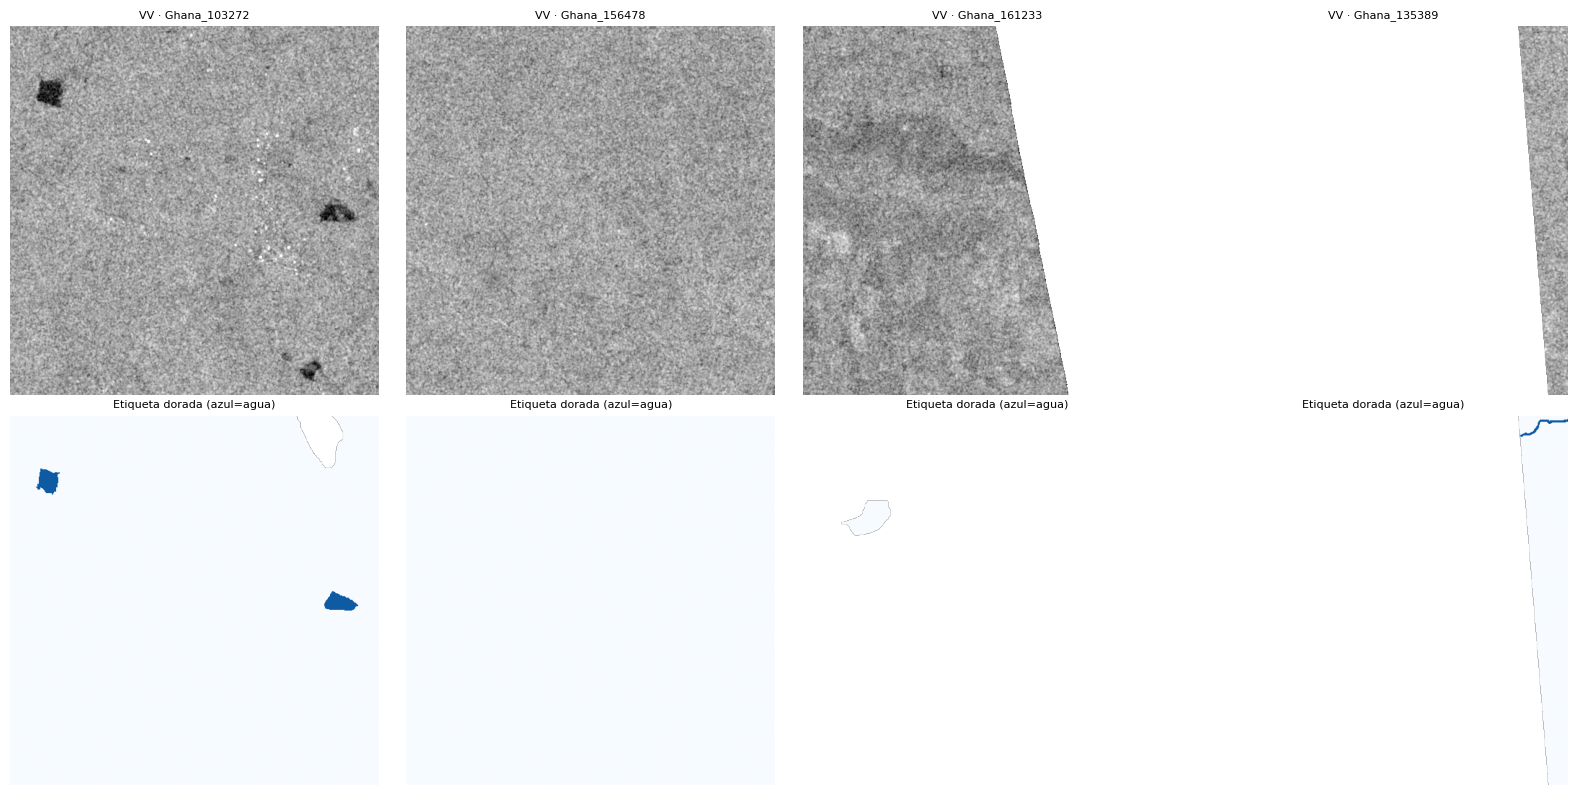

In [10]:
def pixel_sample(S, per_chip=4000, seed=0):
    rng = np.random.default_rng(seed); vv, vh, y = [], [], []
    for x, yy in zip(S.X, S.Y):
        m = (yy >= 0) & np.isfinite(x[0]) & np.isfinite(x[1])
        idx = np.flatnonzero(m.ravel())
        if len(idx) == 0: continue
        idx = rng.choice(idx, size=min(per_chip, len(idx)), replace=False)
        vv.append(x[0].ravel()[idx].astype(np.float32)); vh.append(x[1].ravel()[idx].astype(np.float32))
        y.append(yy.ravel()[idx])
    return np.concatenate(vv), np.concatenate(vh), np.concatenate(y)

def water_fraction(S):
    w = sum(int((y == 1).sum()) for y in S.Y); v = sum(int((y >= 0).sum()) for y in S.Y)
    return w / max(v, 1)

PIX = {k: pixel_sample(S) for k, S in {**D, "weak": W}.items()}
rows = []
for k, (vv, vh, y) in PIX.items():
    rows.append(dict(particion=k, chips=len(D[k]) if k in D else len(W),
                     frac_agua=water_fraction(D[k] if k in D else W),
                     VV_agua=vv[y == 1].mean(), VV_noagua=vv[y == 0].mean(),
                     VH_agua=vh[y == 1].mean(), VH_noagua=vh[y == 0].mean()))
DOM = pd.DataFrame(rows).set_index("particion")
DOM.round(3).to_csv(OUT / "estadistica_particiones.csv")
display(DOM.round(3))
print("Desbalance: proporción de píxeles de agua en train dorado = %.3f → relación no-agua:agua ≈ %.1f:1"
      % (DOM.loc["train", "frac_agua"], (1 - DOM.loc["train", "frac_agua"]) / DOM.loc["train", "frac_agua"]))

fig, ax = plt.subplots(2, 4, figsize=(16, 8))
for j, i in enumerate([0, 7, 15, 30]):
    S = D["train"]; i = min(i, len(S) - 1)
    ax[0, j].imshow(S.X[i][0].astype(np.float32), cmap="gray", vmin=-25, vmax=0); ax[0, j].set_title(f"VV · {S.keys[i]}", fontsize=8)
    ax[1, j].imshow(np.ma.masked_where(S.Y[i] < 0, S.Y[i]), cmap="Blues", vmin=0, vmax=1.2); ax[1, j].set_title("Etiqueta dorada (azul=agua)", fontsize=8)
    for a in ax[:, j]: a.axis("off")
plt.tight_layout(); savefig("00_ejemplos_datos"); plt.show()

### 3. Ítem 1 — U-Net personalizada en PyTorch (entrada VV, VH)

Implementación propia (sin bibliotecas de segmentación): codificador de `depth` bloques `DoubleConv` (Conv3×3 → BatchNorm → ReLU, dos veces) con MaxPool 2×2, cuello de botella, decodificador con `ConvTranspose2d` 2×2 y **conexiones de salto por concatenación**. La red devuelve **logits**; la sigmoide se aplica en la pérdida y en la inferencia (más estable numéricamente con `BCEWithLogits` y precisión mixta).

In [11]:
class DoubleConv(nn.Module):
    """(Conv3x3 -> BatchNorm -> ReLU) x 2"""
    def __init__(self, cin, cout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))
    def forward(self, x): return self.net(x)

class UNet(nn.Module):
    def __init__(self, in_ch=2, out_ch=1, base=64, depth=4):
        super().__init__()
        feats = [base * 2 ** i for i in range(depth)]
        self.downs, self.ups = nn.ModuleList(), nn.ModuleList()
        self.pool = nn.MaxPool2d(2, 2)
        c = in_ch
        for f in feats:
            self.downs.append(DoubleConv(c, f)); c = f
        self.bottleneck = DoubleConv(feats[-1], feats[-1] * 2)
        for f in reversed(feats):
            self.ups.append(nn.ConvTranspose2d(f * 2, f, kernel_size=2, stride=2))
            self.ups.append(DoubleConv(f * 2, f))
        self.head = nn.Conv2d(feats[0], out_ch, kernel_size=1)

    def forward(self, x):
        skips = []
        for down in self.downs:
            x = down(x); skips.append(x); x = self.pool(x)
        x = self.bottleneck(x)
        for i in range(0, len(self.ups), 2):
            x = self.ups[i](x)
            s = skips[-(i // 2 + 1)]
            if x.shape[-2:] != s.shape[-2:]:
                x = F.interpolate(x, size=s.shape[-2:], mode="bilinear", align_corners=False)
            x = self.ups[i + 1](torch.cat([s, x], dim=1))
        return self.head(x)          # logits (B,1,H,W)

def build_model(in_ch=2):
    return UNet(in_ch=in_ch, base=CFG["base"], depth=CFG["depth"]).to(device)

_m = build_model(2)
with torch.no_grad():
    _y = _m.eval()(torch.randn(2, 2, 256, 256, device=device))
print("Entrada (B,2,256,256) -> salida", tuple(_y.shape),
      "| parámetros entrenables: {:,}".format(sum(p.numel() for p in _m.parameters() if p.requires_grad)))
del _m, _y

Entrada (B,2,256,256) -> salida (2, 1, 256, 256) | parámetros entrenables: 31,037,057


### 4. Funciones de pérdida, dataset y utilidades de entrenamiento

Todas las pérdidas **enmascaran los píxeles sin datos** (`-1`). Tres opciones para la ablación (§5):

- **BCE:** entropía cruzada binaria estándar por píxel.
- **Dice:** `1 − (2·Σp·y + ε)/(Σp + Σy + ε)`, con `ε = 1e-6`, calculada sobre todo el lote.
- **Combinada:** `BCE ponderada (pos_weight = relación no-agua/agua del train, acotada a 10) + Dice`, con pesos iguales a 1.

In [12]:
def masked_bce(logits, t, valid, pos_weight=None):
    pw = None if pos_weight is None else torch.as_tensor(pos_weight, device=logits.device, dtype=logits.dtype)
    l = F.binary_cross_entropy_with_logits(logits, t, reduction="none", pos_weight=pw)
    return (l * valid).sum() / valid.sum().clamp(min=1)

def masked_dice(logits, t, valid, eps=1e-6):
    p = torch.sigmoid(logits) * valid; tt = t * valid
    return 1 - (2 * (p * tt).sum() + eps) / (p.sum() + tt.sum() + eps)

# pos_weight a partir de la prevalencia real del train dorado
_wf = water_fraction(D["train"])
POS_WEIGHT = float(min((1 - _wf) / _wf, 10.0))
print(f"Fracción de agua train dorado = {_wf:.3f}  ->  pos_weight = {POS_WEIGHT:.2f}")

def make_loss(name):
    if name == "bce":      return lambda lg, t, v: masked_bce(lg, t, v)
    if name == "dice":     return lambda lg, t, v: masked_dice(lg, t, v)
    if name == "combined": return lambda lg, t, v: masked_bce(lg, t, v, POS_WEIGHT) + masked_dice(lg, t, v)
    raise ValueError(name)

class ChipDS(Dataset):
    def __init__(self, X, Y, mean, std, train=False, crop=256):
        self.X, self.Y, self.train, self.crop = X, Y, train, crop
        self.mean = np.asarray(mean, np.float32).reshape(-1, 1, 1); self.std = np.asarray(std, np.float32).reshape(-1, 1, 1)
    def __len__(self): return len(self.X)
    def __getitem__(self, i):
        x, y = self.X[i], self.Y[i]
        if self.train:
            c = self.crop; r = np.random.randint(0, 512 - c + 1); s = np.random.randint(0, 512 - c + 1)
            x, y = x[:, r:r + c, s:s + c], y[r:r + c, s:s + c]
            if np.random.rand() < .5: x, y = x[:, :, ::-1], y[:, ::-1]
            if np.random.rand() < .5: x, y = x[:, ::-1, :], y[::-1, :]
            k = np.random.randint(4); x, y = np.rot90(x, k, axes=(1, 2)), np.rot90(y, k)
        x = (x.astype(np.float32) - self.mean) / self.std
        x = np.clip(np.nan_to_num(x, nan=0.0), -10, 10)
        return torch.from_numpy(np.ascontiguousarray(x)), torch.from_numpy(np.ascontiguousarray(y).astype(np.float32))

def _winit(_): np.random.seed(torch.initial_seed() % 2 ** 32)

# ------------------------------- métricas -------------------------------
def agg_metrics(probs, Ys, thr=0.5, keys=None):
    """Métricas de la clase 'agua'. Medias por chip (como los autores) y acumuladas (píxeles)."""
    per, TP = [], [0, 0, 0, 0]
    for p, y in zip(probs, Ys):
        valid = y >= 0; gt = (y == 1); pr = (p > thr) & valid
        tp = int((pr & gt).sum()); fp = int((pr & ~gt & valid).sum()); fn = int((~pr & gt).sum())
        tn = int(valid.sum()) - tp - fp - fn
        for j, v in enumerate((tp, fp, fn, tn)): TP[j] += v
        u = tp + fp + fn
        per.append(dict(iou=tp / u if u else np.nan,
                        precision=tp / (tp + fp) if tp + fp else np.nan,
                        recall=tp / (tp + fn) if tp + fn else np.nan,
                        f1=2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else np.nan,
                        tp=tp, fp=fp, fn=fn, tn=tn))
    df = pd.DataFrame(per)
    if keys is not None: df.insert(0, "key", list(keys))
    tp, fp, fn, tn = TP
    out = {k: float(np.nanmean(df[k])) for k in ("iou", "f1", "precision", "recall")}
    out.update(pooled_iou=tp / max(tp + fp + fn, 1), pooled_f1=2 * tp / max(2 * tp + fp + fn, 1),
               omission=fn / max(tp + fn, 1), commission=fp / max(tp + fp, 1),
               cm=[[tn, fp], [fn, tp]], n_chips=len(df), per_chip=df)
    return out

@torch.no_grad()
def predict(model, S_X, mean, std, bs=8):
    model.eval(); ds = ChipDS(S_X, [np.zeros((512, 512), np.int8)] * len(S_X), mean, std)
    out = []
    for x, _ in DataLoader(ds, batch_size=bs, shuffle=False, num_workers=0):
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            lg = model(x.to(device))
        out.append(torch.sigmoid(lg.float()).squeeze(1).cpu().numpy().astype(np.float16))
    return np.concatenate(out)

def boot_ci(v, n=2000, seed=0):
    v = np.asarray(v, float); v = v[~np.isnan(v)]; rng = np.random.default_rng(seed)
    m = [rng.choice(v, len(v)).mean() for _ in range(n)]
    return float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5))

Fracción de agua train dorado = 0.095  ->  pos_weight = 9.52


In [13]:
def train_generic(name, in_ch, mean, std, phases, loss_name, val, evals, verbose=True):
    """
    phases: lista de (X, Y, iters, lr) -> se entrenan en secuencia (p. ej. preentrenamiento débil y luego ajuste dorado).
    val   : (X, Y) para seleccionar el mejor punto (IoU medio por chip). evals: {nombre: (X, Y, keys)} evaluados al final.
    """
    seed_everything(CFG["seed"]); t0 = time.time()
    model = build_model(in_ch); loss_fn = make_loss(loss_name)
    try:
        scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    except AttributeError:                       # PyTorch < 2.3
        scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
    best = dict(iou=-1, state=None, step=None); hist = []; step_total = 0
    for pi, (X, Y, iters, lr) in enumerate(phases):
        ds = ChipDS(X, Y, mean, std, train=True, crop=CFG["crop"])
        bs = min(CFG["batch_size"], len(ds))
        loader = DataLoader(ds, batch_size=bs, shuffle=True, drop_last=len(ds) >= bs,
                            num_workers=CFG["workers"], worker_init_fn=_winit,
                            persistent_workers=CFG["workers"] > 0)
        opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=CFG["wd"])
        warm = max(1, int(0.05 * iters))
        sched = torch.optim.lr_scheduler.LambdaLR(
            opt, lambda s: min(1.0, (s + 1) / warm) * 0.5 * (1 + math.cos(math.pi * min(s, iters) / iters)))
        it, run_loss, nl = 0, 0.0, 0
        model.train()
        while it < iters:
            for x, y in loader:
                x = x.to(device, non_blocking=True); y = y.to(device).unsqueeze(1)
                valid = (y >= 0).float(); t = y.clamp(min=0)
                with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                    lg = model(x)
                loss = loss_fn(lg.float(), t, valid)
                opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
                it += 1; step_total += 1; run_loss += loss.item(); nl += 1
                if it % CFG["eval_every"] == 0 or it == iters:
                    pv = predict(model, val[0], mean, std)
                    m = agg_metrics(pv, val[1], CFG["thr"])
                    hist.append(dict(run=name, fase=pi + 1, iter=step_total, loss=run_loss / nl, val_iou=m["iou"], val_f1=m["f1"]))
                    if verbose: print(f"[{name}] fase {pi+1} it {it}/{iters} | loss {run_loss/nl:.4f} | val IoU {m['iou']:.4f} F1 {m['f1']:.4f}")
                    run_loss, nl = 0.0, 0
                    if m["iou"] > best["iou"]:
                        best = dict(iou=m["iou"], step=step_total, state={k: v.detach().cpu().clone() for k, v in model.state_dict().items()})
                    model.train()
                if it >= iters: break
        del loader
    model.load_state_dict(best["state"])
    res = dict(name=name, history=pd.DataFrame(hist), best_val_iou=best["iou"], best_step=best["step"],
               model=model, metrics={}, probs={})
    for k, (Xe, Ye, ke) in evals.items():
        p = predict(model, Xe, mean, std); res["probs"][k] = p
        res["metrics"][k] = agg_metrics(p, Ye, CFG["thr"], ke)
    res["minutes"] = (time.time() - t0) / 60
    if verbose: print(f"[{name}] listo en {res['minutes']:.1f} min | mejor val IoU {best['iou']:.4f} (paso {best['step']})")
    return res

EVALS = {k: (D[k].X, D[k].Y, D[k].keys) for k in ("valid", "test", "bolivia")}
VAL = (D["valid"].X, D["valid"].Y)
G = D["train"]

### 5. Ítem 2 — Estudio de ablación

Dos decisiones, con el mismo presupuesto de **iteraciones** (`iters`) en todos los casos para que la comparación sea justa:

**(a) Estrategia de supervisión** (pérdida combinada fija):
- `G` — solo chips dorados del train oficial.
- `G+W` — dorados + chips débiles mezclados en el mismo entrenamiento.
- `W→G` — preentrenamiento con débiles (mitad de iteraciones) y ajuste fino con dorados (mitad, `lr × 0.3`).

**(b) Función de pérdida** (BCE, Dice, combinada) con la **mejor estrategia de (a) según IoU de validación**.

La selección usa **solo validación**; prueba y Bolivia se reportan pero **no** se usan para elegir.

In [14]:
RUNS = {}
def phases_for(regime, iters, lr):
    if regime == "G":   return [(G.X, G.Y, iters, lr)]
    if regime == "G+W": return [(G.X + W.X, G.Y + W.Y, iters, lr)]
    if regime == "W→G": return [(W.X, W.Y, iters // 2, lr), (G.X, G.Y, iters // 2, lr * 0.3)]

def run(regime, loss_name):
    name = f"{regime}|{loss_name}"
    if name not in RUNS:
        RUNS[name] = train_generic(name, 2, MEAN_S1, STD_S1, phases_for(regime, CFG["iters"], CFG["lr"]),
                                   loss_name, VAL, EVALS)
        RUNS[name]["regime"], RUNS[name]["loss"] = regime, loss_name
    return RUNS[name]

# ---- (a) supervisión ----
for reg in ["G", "G+W", "W→G"]:
    run(reg, "combined")
best_regime = max(["G", "G+W", "W→G"], key=lambda r: RUNS[f"{r}|combined"].get("best_val_iou"))
print("\n>> Mejor estrategia de supervisión (val IoU):", best_regime)

# ---- (b) función de pérdida ----
for ln in ["bce", "dice"]:
    run(best_regime, ln)
best_name = max(RUNS, key=lambda n: RUNS[n]["best_val_iou"])
print(">> Mejor configuración global (val IoU):", best_name)

[G|combined] fase 1 it 100/600 | loss 1.2785 | val IoU 0.3108 F1 0.4110
[G|combined] fase 1 it 200/600 | loss 1.1046 | val IoU 0.3348 F1 0.4358
[G|combined] fase 1 it 300/600 | loss 1.0636 | val IoU 0.3268 F1 0.4313
[G|combined] fase 1 it 400/600 | loss 1.0901 | val IoU 0.3622 F1 0.4677
[G|combined] fase 1 it 500/600 | loss 1.0342 | val IoU 0.3761 F1 0.4825
[G|combined] fase 1 it 600/600 | loss 0.9738 | val IoU 0.3705 F1 0.4759
[G|combined] listo en 5.2 min | mejor val IoU 0.3761 (paso 500)
[G+W|combined] fase 1 it 100/600 | loss 1.0750 | val IoU 0.3155 F1 0.4051
[G+W|combined] fase 1 it 200/600 | loss 0.8363 | val IoU 0.3264 F1 0.4163
[G+W|combined] fase 1 it 300/600 | loss 0.7831 | val IoU 0.3258 F1 0.4180
[G+W|combined] fase 1 it 400/600 | loss 0.7385 | val IoU 0.3335 F1 0.4263
[G+W|combined] fase 1 it 500/600 | loss 0.7650 | val IoU 0.3368 F1 0.4305
[G+W|combined] fase 1 it 600/600 | loss 0.6591 | val IoU 0.3417 F1 0.4355
[G+W|combined] listo en 4.8 min | mejor val IoU 0.3417 (paso

,Supervisión,Pérdida,Val IoU,Test IoU,Test F1,Test Prec,Test Recall,Bolivia IoU,Minutos
Experimento,,,,,,,,,
G|combined,G,combined,0.3761,0.3829,0.4919,0.4669,0.6976,0.3687,5.2168
G+W|combined,G+W,combined,0.3417,0.3471,0.4364,0.4840,0.6014,0.4656,4.8157
W→G|combined,W→G,combined,0.3668,0.3604,0.4645,0.4484,0.7103,0.4115,4.8555
G|bce,G,bce,0.3642,0.3698,0.4638,0.5678,0.5500,0.4327,4.8470
G|dice,G,dice,0.3852,0.3777,0.4811,0.5261,0.5841,0.3777,4.8216


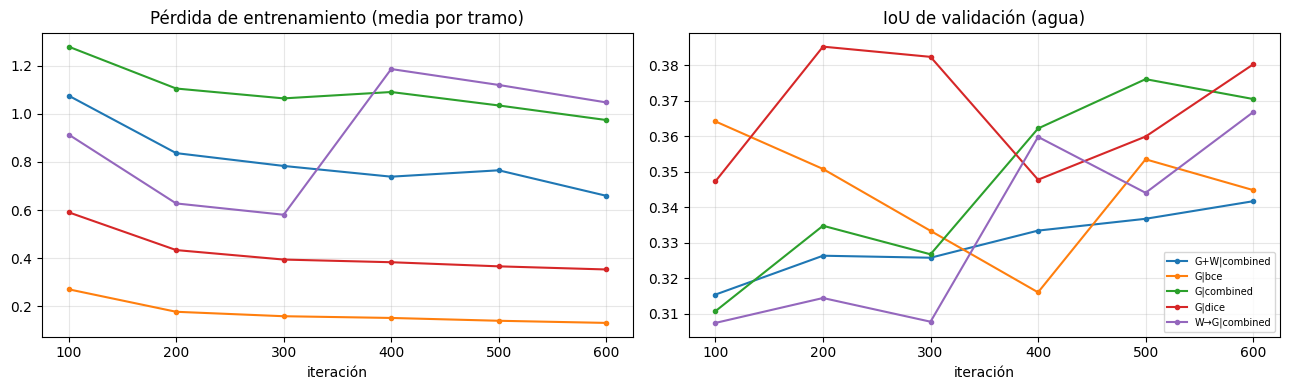

In [19]:
rows = []
for n, r in RUNS.items():
    t, b, v = r["metrics"]["test"], r["metrics"]["bolivia"], r["metrics"]["valid"]
    rows.append({"Experimento": n, "Supervisión": r["regime"], "Pérdida": r["loss"],
                 "Val IoU": v["iou"], "Test IoU": t["iou"], "Test F1": t["f1"], "Test Prec": t["precision"],
                 "Test Recall": t["recall"], "Bolivia IoU": b["iou"], "Minutos": r["minutes"]})
ABL = pd.DataFrame(rows).set_index("Experimento")
ABL.round(4).to_csv(OUT / "ablacion.csv"); display(ABL.round(4))

hist = pd.concat([r["history"] for r in RUNS.values()])
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for n, h in hist.groupby("run"):
    ax[0].plot(h.iter, h.loss, marker="o", ms=3, label=n); ax[1].plot(h.iter, h.val_iou, marker="o", ms=3, label=n)
ax[0].set_title("Pérdida de entrenamiento (media por tramo)"); ax[1].set_title("IoU de validación (agua)")
for a in ax: a.set_xlabel("iteración"); a.grid(alpha=.3)
ax[1].legend(fontsize=7); plt.tight_layout(); savefig("01_ablacion_curvas"); plt.show()

### 6. Ítem 3 — Evaluación en distribución (chips dorados de eventos vistos)

Conjunto: partición oficial `test` (chips dorados de los mismos eventos presentes en entrenamiento). Modelo: la **mejor configuración por IoU de validación**. Umbral de binarización: 0.5 (fijo). IoU/F1/precisión/recall se reportan como **media por chip** (criterio de los autores del dataset) y entre paréntesis acumulados sobre píxeles; omisión = FN/(TP+FN), comisión = FP/(TP+FP).

Modelo final: G|dice  (90 chips de prueba)
IoU  0.3777 (acum. 0.6425) | F1 0.4811 (acum. 0.7823)
Precisión 0.5261 | Recall 0.5841 | Omisión 0.2228 | Comisión 0.2125
IC95% bootstrap del IoU medio por chip: [0.314, 0.440]


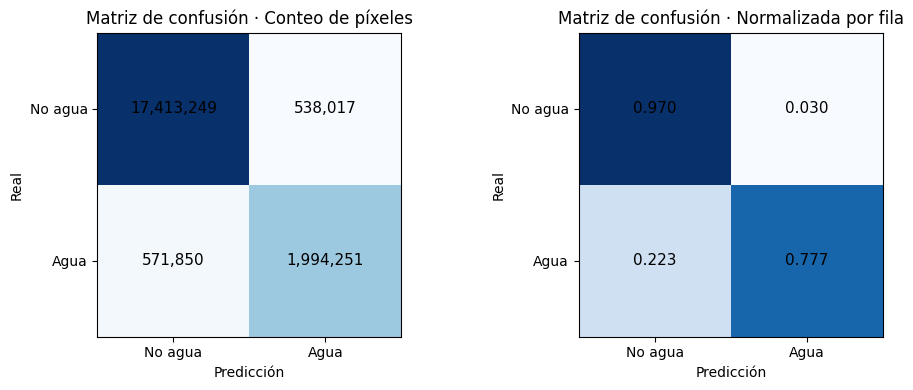


Lectura de la matriz (píxeles de prueba, eventos vistos):
 - De cada 100 píxeles de agua real, el modelo detecta 77.7 (verdaderos positivos) y omite 22.3 (falsos negativos).
 - De cada 100 píxeles predichos como agua, 21.2 son falsas alarmas (falsos positivos).
 - Los verdaderos negativos dominan el conteo (17,413,249) por el desbalance de clases; por eso la exactitud global no es informativa y se usa IoU/F1 de la clase agua.



,iou,f1,precision,recall,chips
evento,,,,,
Ghana,0.266,0.349,0.593,0.398,11
India,0.449,0.556,0.618,0.581,14
Mekong,0.444,0.534,0.559,0.609,6
Nigeria,0.379,0.487,0.604,0.596,4
Pakistan,0.152,0.238,0.283,0.577,6
Paraguay,0.422,0.528,0.541,0.681,14
Somalia,0.234,0.315,0.432,0.259,6
Spain,0.487,0.599,0.545,0.719,6
Sri-Lanka,0.418,0.512,0.552,0.561,9


In [20]:
FINAL = RUNS[best_name]
mt = FINAL["metrics"]["test"]
print(f"Modelo final: {best_name}  ({mt['n_chips']} chips de prueba)")
print(f"IoU  {mt['iou']:.4f} (acum. {mt['pooled_iou']:.4f}) | F1 {mt['f1']:.4f} (acum. {mt['pooled_f1']:.4f})")
print(f"Precisión {mt['precision']:.4f} | Recall {mt['recall']:.4f} | Omisión {mt['omission']:.4f} | Comisión {mt['commission']:.4f}")
lo, hi = boot_ci(mt["per_chip"]["iou"]); print(f"IC95% bootstrap del IoU medio por chip: [{lo:.3f}, {hi:.3f}]")

(tn, fp), (fn, tp) = mt["cm"]; cm = np.array([[tn, fp], [fn, tp]], float)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (M, ttl, fmt) in zip(ax, [(cm, "Conteo de píxeles", "{:,.0f}"), (cm / cm.sum(1, keepdims=True), "Normalizada por fila", "{:.3f}")]):
    a.imshow(M if ttl.startswith("Normal") else np.log10(M + 1), cmap="Blues")
    for i in range(2):
        for j in range(2): a.text(j, i, fmt.format(M[i, j]), ha="center", va="center", color="black", fontsize=11)
    a.set_xticks([0, 1], ["No agua", "Agua"]); a.set_yticks([0, 1], ["No agua", "Agua"])
    a.set_xlabel("Predicción"); a.set_ylabel("Real"); a.set_title(f"Matriz de confusión · {ttl}")
plt.tight_layout(); savefig("02_matriz_confusion_test"); plt.show()

print(f"""
Lectura de la matriz (píxeles de prueba, eventos vistos):
 - De cada 100 píxeles de agua real, el modelo detecta {100*(1-mt['omission']):.1f} (verdaderos positivos) y omite {100*mt['omission']:.1f} (falsos negativos).
 - De cada 100 píxeles predichos como agua, {100*mt['commission']:.1f} son falsas alarmas (falsos positivos).
 - Los verdaderos negativos dominan el conteo ({tn:,}) por el desbalance de clases; por eso la exactitud global no es informativa y se usa IoU/F1 de la clase agua.
""")

ev = mt["per_chip"].assign(evento=[k.split("_")[0] for k in mt["per_chip"].key])
EV_TEST = ev.groupby("evento")[["iou", "f1", "precision", "recall"]].mean().assign(chips=ev.groupby("evento").size())
EV_TEST.round(3).to_csv(OUT / "test_por_evento.csv"); display(EV_TEST.round(3))

### 7. Ítem 4 — Generalización geográfica: entrenar sin Bolivia, evaluar solo en Bolivia

El entrenamiento de **todos** los modelos usa únicamente la partición oficial `train` (que no contiene Bolivia) y chips débiles **sin** Bolivia. Por tanto, el modelo final ya cumple el protocolo "entrenar excluyendo Bolivia"; aquí se verifica y se mide la brecha frente a §6. Los 15 chips dorados de Bolivia son pocos: se reporta intervalo bootstrap y hay que leer las diferencias con cautela.

In [21]:
# Verificación explícita: Bolivia no aparece en ningún conjunto de entrenamiento
assert not any(e == "Bolivia" for e in G.events), "Bolivia en train dorado"
assert not any(e == "Bolivia" for e in W.events), "Bolivia en débiles"
assert not (set(G.keys) & set(D["bolivia"].keys)), "chips repetidos entre train y Bolivia"
print("OK: Bolivia excluida del entrenamiento (dorado y débil). Eventos de train:", sorted(set(G.events)))

mb = FINAL["metrics"]["bolivia"]
rows = []
for k, lab in [("iou", "IoU (media por chip)"), ("f1", "F1"), ("precision", "Precisión"), ("recall", "Recall"),
               ("omission", "Omisión (FN)"), ("commission", "Comisión (FP)")]:
    a, b = mt[k], mb[k]; rows.append({"Métrica": lab, "En distribución (test)": a, "Bolivia": b,
                                      "Δ absoluto": b - a,
                                      "Δ relativo %": 100 * (b - a) / a if (a and k in ("iou", "f1", "precision", "recall")) else np.nan})
GAP = pd.DataFrame(rows).set_index("Métrica"); GAP.round(4).to_csv(OUT / "brecha_bolivia.csv"); display(GAP.round(4))
ci_t, ci_b = boot_ci(mt["per_chip"]["iou"]), boot_ci(mb["per_chip"]["iou"])
print(f"IoU test {mt['iou']:.3f} IC95% [{ci_t[0]:.3f},{ci_t[1]:.3f}] | Bolivia {mb['iou']:.3f} IC95% [{ci_b[0]:.3f},{ci_b[1]:.3f}] (n={mb['n_chips']} chips)")
display(mb["per_chip"][["key", "iou", "precision", "recall", "f1"]].round(3))

OK: Bolivia excluida del entrenamiento (dorado y débil). Eventos de train: ['Ghana', 'India', 'Mekong', 'Nigeria', 'Pakistan', 'Paraguay', 'Somalia', 'Spain', 'Sri-Lanka', 'USA']


,En distribución (test),Bolivia,Δ absoluto,Δ relativo %
Métrica,,,,
IoU (media por chip),0.3777,0.3777,-0.0000,-0.0004
F1,0.4811,0.4752,-0.0060,-1.2375
Precisión,0.5261,0.5622,0.0361,6.8593
Recall,0.5841,0.4514,-0.1327,-22.7170
Omisión (FN),0.2228,0.3032,0.0803,NaN
Comisión (FP),0.2125,0.1473,-0.0651,NaN


IoU test 0.378 IC95% [0.314,0.440] | Bolivia 0.378 IC95% [0.221,0.522] (n=15 chips)


,key,iou,precision,recall,f1
0,Bolivia_103757,0.792,0.909,0.861,0.884
1,Bolivia_129334,0.834,0.941,0.880,0.909
2,Bolivia_195474,0.013,0.035,0.021,0.026
3,Bolivia_23014,0.584,0.598,0.960,0.737
4,Bolivia_233925,0.000,0.000,0.000,0.000
5,Bolivia_242570,0.304,0.593,0.385,0.467
6,Bolivia_290290,0.315,0.761,0.350,0.479
7,Bolivia_294583,0.729,0.749,0.966,0.843
8,Bolivia_312675,0.082,0.697,0.085,0.152
9,Bolivia_314919,0.606,0.890,0.655,0.755


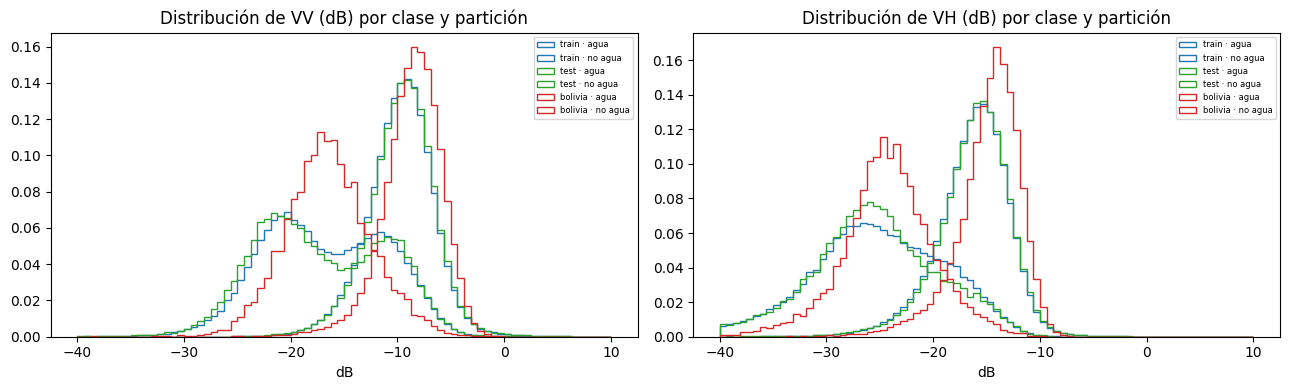

Estadística de las particiones (dB):


,chips,frac_agua,VV_agua,VV_noagua,VH_agua,VH_noagua
particion,,,,,,
train,252,0.095,-16.861000,-9.744,-25.686001,-16.386999
test,90,0.125,-17.221001,-9.673,-26.035999,-16.327999
bolivia,15,0.159,-16.521000,-8.680,-24.431999,-14.923000



Lectura automática (revisar y redactar en el informe):
 - Retrodispersión media del AGUA en VV:  train -16.86 dB | test -17.22 dB | Bolivia -16.52 dB
   (Δ Bolivia–train = +0.34 dB; un agua más brillante en Bolivia apoyaría la hipótesis de vegetación inundada / dispersión por volumen).
 - Retrodispersión media del AGUA en VH:  train -25.69 | Bolivia -24.43 dB (Δ = +1.25 dB).
 - Fracción de agua: train 0.095 | test 0.125 | Bolivia 0.159.
 - Tipo de error dominante en Bolivia: omisión 0.303 vs. comisión 0.147 -> predominan los falsos negativos (agua no detectada).



In [22]:
# ---- Evidencia empírica para las hipótesis (estadística de retrodispersión por partición) ----
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
cols = {"train": "tab:blue", "test": "tab:green", "bolivia": "tab:red"}
for band, a, nm in [(0, ax[0], "VV"), (1, ax[1], "VH")]:
    for k, c in cols.items():
        vv, vh, y = PIX[k]; v = (vv, vh)[band]
        a.hist(v[y == 1], bins=80, range=(-40, 10), density=True, histtype="step", color=c, lw=1.8, label=f"{k} · agua")
        a.hist(v[y == 0], bins=80, range=(-40, 10), density=True, histtype="step", color=c, lw=1.0, ls="--", label=f"{k} · no agua")
    a.set_title(f"Distribución de {nm} (dB) por clase y partición"); a.set_xlabel("dB"); a.legend(fontsize=6)
plt.tight_layout(); savefig("03_hist_retrodispersion"); plt.show()

d = DOM.loc
print("Estadística de las particiones (dB):"); display(DOM.loc[["train", "test", "bolivia"]].round(3))
print(f"""
Lectura automática (revisar y redactar en el informe):
 - Retrodispersión media del AGUA en VV:  train {d['train','VV_agua']:.2f} dB | test {d['test','VV_agua']:.2f} dB | Bolivia {d['bolivia','VV_agua']:.2f} dB
   (Δ Bolivia–train = {d['bolivia','VV_agua']-d['train','VV_agua']:+.2f} dB; un agua más brillante en Bolivia apoyaría la hipótesis de vegetación inundada / dispersión por volumen).
 - Retrodispersión media del AGUA en VH:  train {d['train','VH_agua']:.2f} | Bolivia {d['bolivia','VH_agua']:.2f} dB (Δ = {d['bolivia','VH_agua']-d['train','VH_agua']:+.2f} dB).
 - Fracción de agua: train {d['train','frac_agua']:.3f} | test {d['test','frac_agua']:.3f} | Bolivia {d['bolivia','frac_agua']:.3f}.
 - Tipo de error dominante en Bolivia: omisión {mb['omission']:.3f} vs. comisión {mb['commission']:.3f} -> {'predominan los falsos negativos (agua no detectada)' if mb['omission']>mb['commission'] else 'predominan los falsos positivos (agua falsa)'}.
""")

#### Hipótesis sobre la brecha (a contrastar con las cifras de arriba)

- **H1 — Cobertura del suelo: vegetación inundada y humedales.** En Bolivia (llanuras amazónicas) el agua bajo vegetación emergente produce dispersión por volumen y doble rebote tallo–agua, elevando la retrodispersión y haciendo que el agua deje de verse oscura. *Evidencia a mirar:* retrodispersión media del agua en Bolivia más alta que en train, y omisión (FN) dominante.
- **H2 — Geometría de adquisición (ángulo de incidencia, órbita) y estado del suelo.** Cambia los valores en dB de una misma superficie entre regiones. **Limitación:** los chips distribuidos solo traen VV y VH; **el ángulo de incidencia no está en el dato**, así que H2 no se puede verificar directamente con este cuaderno y debe presentarse como hipótesis.
- **H3 — Diferencia de prevalencia y contexto del evento.** Una fracción de agua distinta (ver tabla) y un único evento con solo 15 chips hacen la métrica muy variable; parte de la brecha puede ser ruido de muestreo (ver IC bootstrap).

> Redactar en el informe qué hipótesis queda apoyada por los números reales y cuál solo se enuncia.

### 8. Ítem 5 — Fallos característicos del SAR con ejemplos reales

Se toman los chips reales de **test + Bolivia** y se identifican los de mayor omisión (FN) y mayor comisión (FP). Cada fila muestra VV, VH, etiqueta, predicción y mapa de errores (**rojo = FP, azul = FN**). Después se cuantifica la **firma de retrodispersión** de cada tipo de error:

- **FN brillantes** (VV > −12 dB): agua que el radar ve brillante → doble rebote (urbano o vegetación inundada) o rugosidad por viento.
- **FP oscuros** (VV < −18 dB): superficies lisas o sin retorno que parecen agua → sombra de radar, pavimento/arena lisa, suelo húmedo.
- **FP o FN de retrodispersión intermedia:** ambigüedad suelo húmedo / agua poco profunda.

> Distinguir con certeza *sombra de radar* exige un DEM, que **no** forma parte de Sen1Floods11: la asignación de cada ejemplo a un tipo se hace por firma de retrodispersión e inspección visual, y así debe declararse en el informe.

,píxeles,VV_medio_dB,VH_medio_dB
TP,2310058.0,-18.58,-27.48
TN,19713994.0,-9.40,-15.92
FP,587490.0,-14.84,-23.66
FN,656851.0,-11.08,-19.24


FN con VV > -12 dB (agua brillante): 62.0% de 656,851 FN
FP con VV < -18 dB (oscuros tipo sombra/liso): 22.2% de 587,490 FP


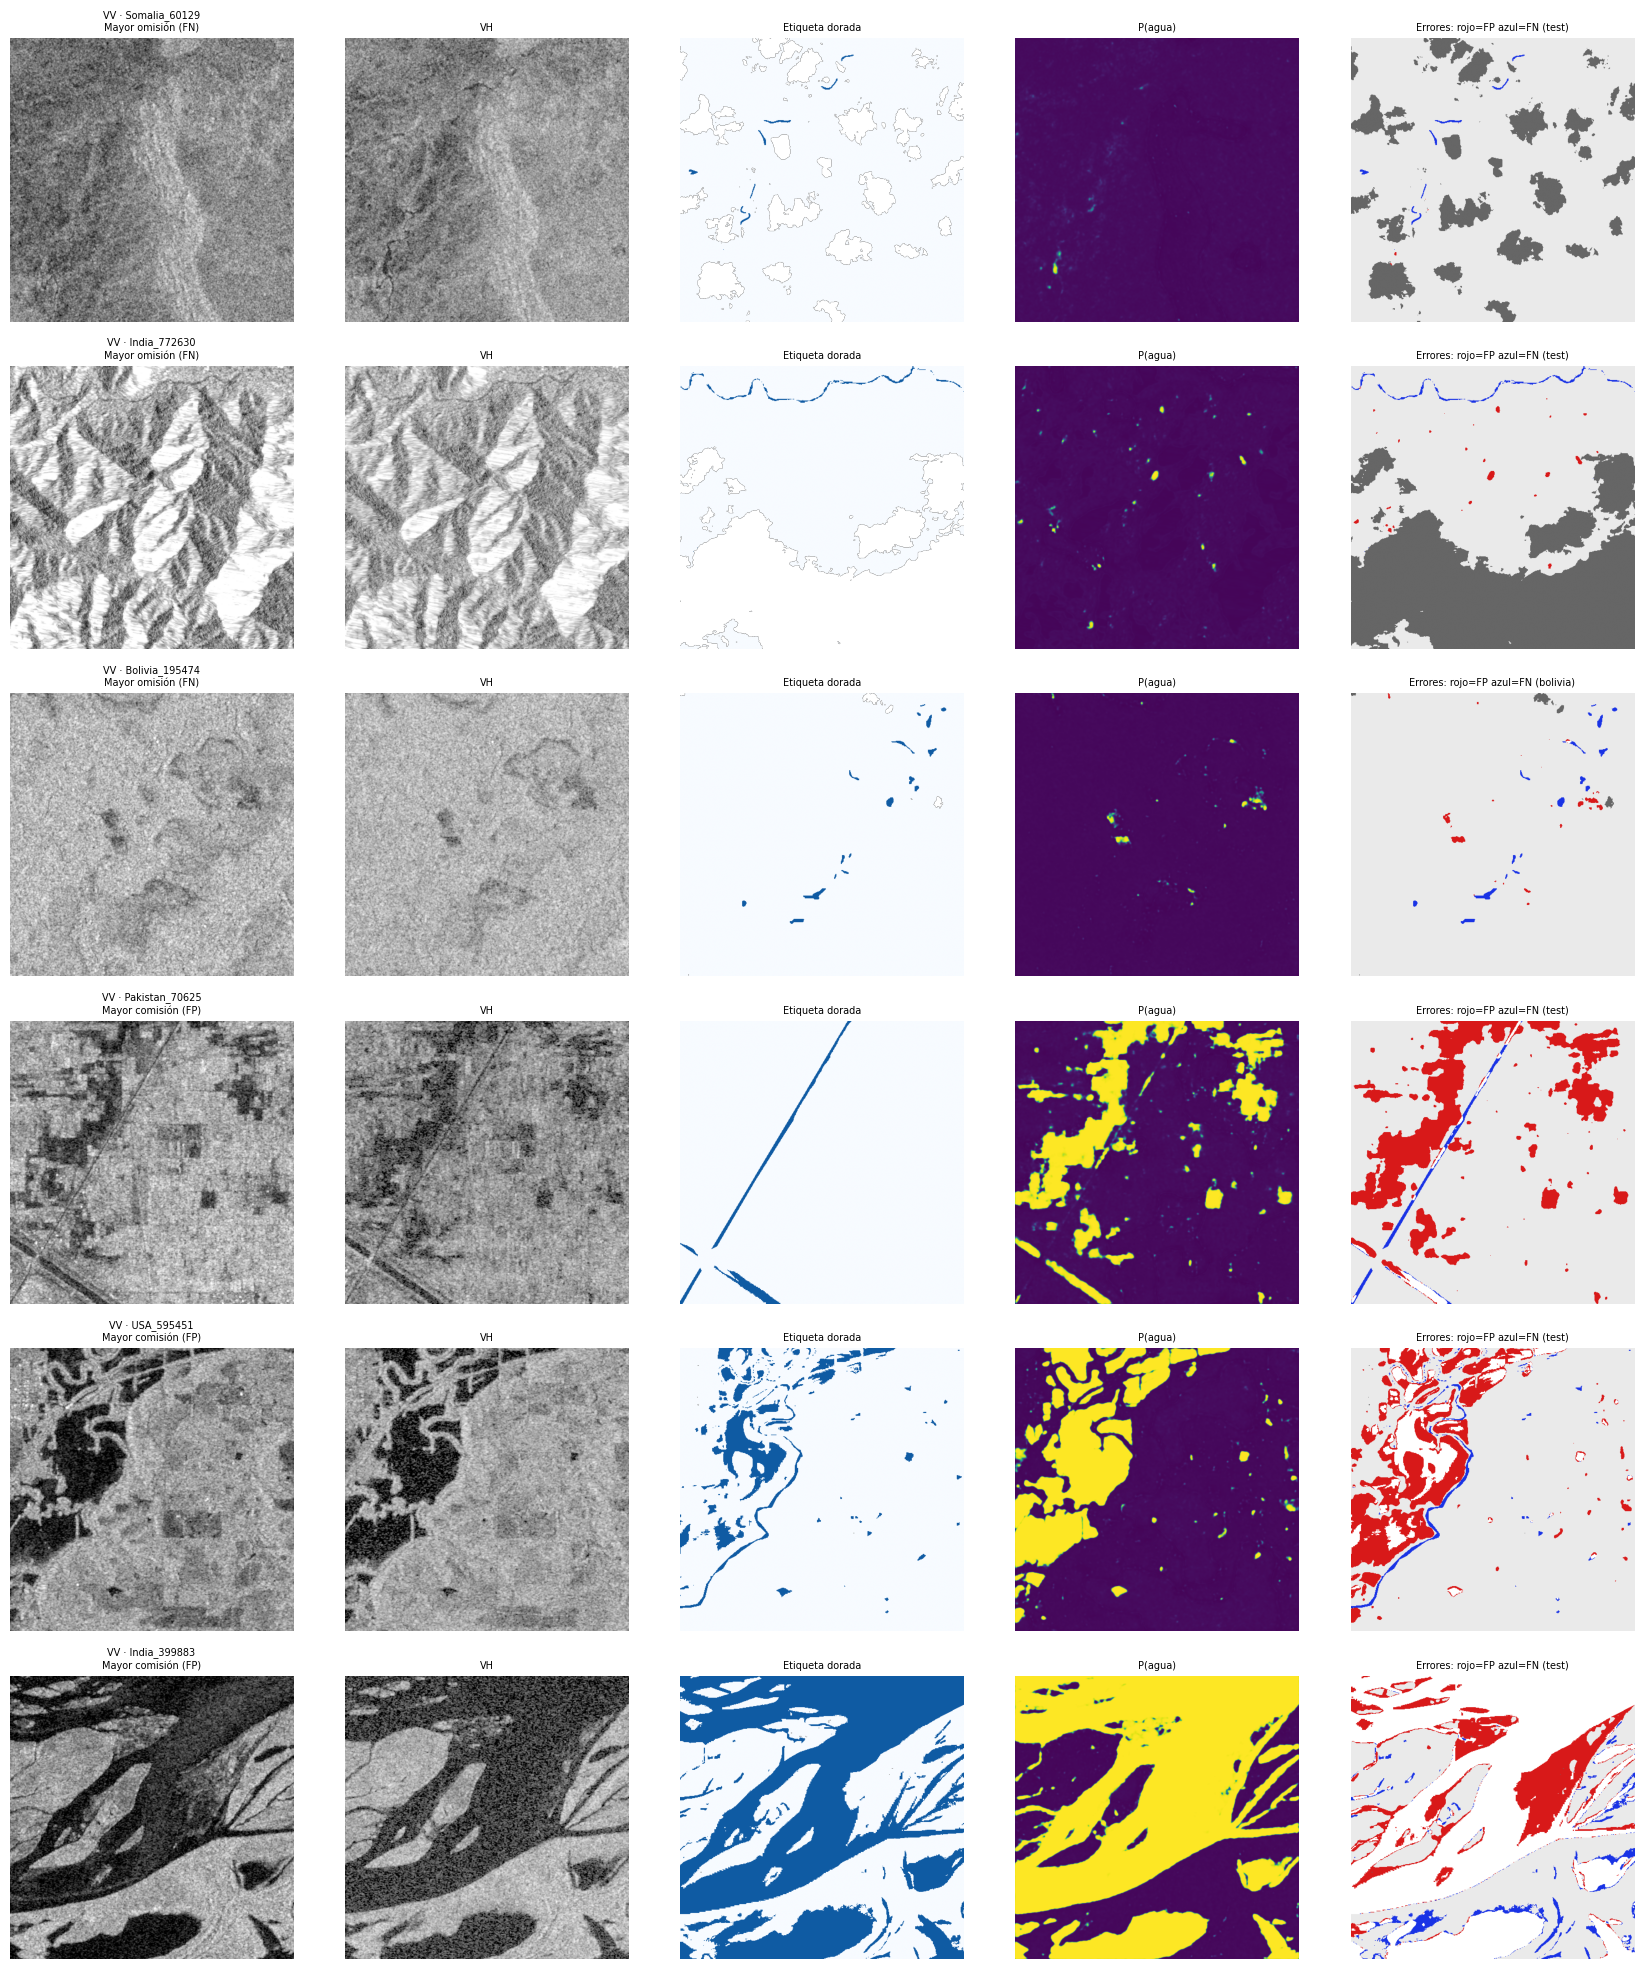

,key,split,fn,fp,water,fn_rate,fp_rate,tipo
56,Somalia_60129,test,677,34,677,1.0000,0.0002,Mayor omisión (FN)
22,India_772630,test,1343,764,1345,0.9985,0.0049,Mayor omisión (FN)
92,Bolivia_195474,bolivia,1518,920,1551,0.9787,0.0035,Mayor omisión (FN)
38,Pakistan_70625,test,2361,43888,4667,0.5059,0.1674,Mayor comisión (FP)
86,USA_595451,test,3108,37097,20531,0.1514,0.1415,Mayor comisión (FP)
24,India_399883,test,7730,32161,136292,0.0567,0.1227,Mayor comisión (FP)


In [23]:
POOL = []  # (clave, split, X, Y, prob)
for k in ("test", "bolivia"):
    for i in range(len(D[k])):
        POOL.append((D[k].keys[i], k, D[k].X[i], D[k].Y[i], FINAL["probs"][k][i]))

stat = {c: dict(n=0, vv=0.0, vh=0.0) for c in ("TP", "TN", "FP", "FN")}
fn_bright = fn_total = fp_dark = fp_total = 0; chip_err = []
for key, sp, x, y, p in POOL:
    valid = (y >= 0) & np.isfinite(x[0]) & np.isfinite(x[1]); gt = (y == 1) & valid; pr = (p > CFG["thr"]) & valid
    cat = {"TP": pr & gt, "FP": pr & ~gt & valid, "FN": ~pr & gt, "TN": ~pr & ~gt & valid}
    vv, vh = x[0].astype(np.float32), x[1].astype(np.float32)
    for c, m in cat.items():
        stat[c]["n"] += int(m.sum()); stat[c]["vv"] += float(vv[m].sum()); stat[c]["vh"] += float(vh[m].sum())
    fn_bright += int((cat["FN"] & (vv > -12)).sum()); fn_total += int(cat["FN"].sum())
    fp_dark += int((cat["FP"] & (vv < -18)).sum()); fp_total += int(cat["FP"].sum())
    chip_err.append(dict(key=key, split=sp, fn=int(cat["FN"].sum()), fp=int(cat["FP"].sum()),
                         water=int(gt.sum()), fn_rate=cat["FN"].sum() / max(gt.sum(), 1), fp_rate=cat["FP"].sum() / max(valid.sum(), 1)))
ERR = pd.DataFrame(chip_err)
SIG = pd.DataFrame({c: dict(píxeles=s["n"], VV_medio_dB=s["vv"] / max(s["n"], 1), VH_medio_dB=s["vh"] / max(s["n"], 1)) for c, s in stat.items()}).T
SIG.round(2).to_csv(OUT / "firma_errores.csv"); display(SIG.round(2))
print(f"FN con VV > -12 dB (agua brillante): {100*fn_bright/max(fn_total,1):.1f}% de {fn_total:,} FN")
print(f"FP con VV < -18 dB (oscuros tipo sombra/liso): {100*fp_dark/max(fp_total,1):.1f}% de {fp_total:,} FP")

top_fn = ERR[ERR.water > 500].sort_values("fn_rate", ascending=False).head(3)
top_fp = ERR.sort_values("fp", ascending=False).head(3)
sel = pd.concat([top_fn.assign(tipo="Mayor omisión (FN)"), top_fp.assign(tipo="Mayor comisión (FP)")])
lookup = {k: (x, y, p) for k, sp, x, y, p in POOL}
fig, ax = plt.subplots(len(sel), 5, figsize=(17, 3.3 * len(sel)))
for r, (_, row) in enumerate(sel.iterrows()):
    x, y, p = lookup[row.key]; pr = p > CFG["thr"]; valid = y >= 0
    err = np.zeros(y.shape + (3,)); err[...] = 0.92
    err[(pr & (y == 0))] = (0.85, 0.1, 0.1); err[(~pr & (y == 1))] = (0.1, 0.2, 0.9); err[(pr & (y == 1))] = (1, 1, 1); err[~valid] = (0.4, 0.4, 0.4)
    ax[r, 0].imshow(x[0].astype(np.float32), cmap="gray", vmin=-25, vmax=0); ax[r, 0].set_title(f"VV · {row.key}\n{row.tipo}", fontsize=7)
    ax[r, 1].imshow(x[1].astype(np.float32), cmap="gray", vmin=-35, vmax=-5); ax[r, 1].set_title("VH", fontsize=7)
    ax[r, 2].imshow(np.ma.masked_where(~valid, y), cmap="Blues", vmin=0, vmax=1.2); ax[r, 2].set_title("Etiqueta dorada", fontsize=7)
    ax[r, 3].imshow(p.astype(np.float32), cmap="viridis", vmin=0, vmax=1); ax[r, 3].set_title("P(agua)", fontsize=7)
    ax[r, 4].imshow(err); ax[r, 4].set_title(f"Errores: rojo=FP azul=FN ({row.split})", fontsize=7)
    for a in ax[r]: a.axis("off")
plt.tight_layout(); savefig("04_fallos_sar"); plt.show()
sel.round(4).to_csv(OUT / "chips_analisis_fallos.csv"); display(sel.round(4))

#### 8.1 Clasificación de los ejemplos (completar tras mirar `04_fallos_sar.png`)

| Chip (clave) | Tipo de error observado | Mecanismo físico propuesto | Evidencia (firma dB / aspecto) |
|---|---|---|---|
| `[clave del chip]` | `[p. ej. FN: agua brillante]` | `[doble rebote / vegetación inundada / viento]` | `[VV medio del error, zona del chip]` |
| `[clave del chip]` | `[p. ej. FP: oscuro]` | `[sombra de radar / superficie lisa / suelo húmedo]` | `[…]` |
| `[clave del chip]` | `[tercer tipo]` | `[…]` | `[…]` |

> No se describe un error como "sombra de radar" o "doble rebote" en el informe si la imagen no lo respalda.

### 9. Ítem 6 (bono) — Fusión SAR + Sentinel-2 en los chips libres de nubes

Se activa con `BONUS = True` (descarga las 4 bandas necesarias de Sentinel-2 de los 446 chips dorados, ~6 GB de transferencia). Se añaden **B2, B3, B4 (azul, verde, rojo) y B8 (NIR)** como 4 canales extra (6 en total). Los **chips con nubes se descartan con una heurística** (fracción de píxeles con reflectancia en azul > 0.25 mayor a `CLOUD_FRAC_MAX`), declarada como tal. Se entrenan **dos modelos con exactamente el mismo subconjunto, receta y semilla**: solo-SAR (2 canales) vs. SAR+óptico (6 canales), con entrenamiento solo en dorados y la mejor pérdida de §5.

In [24]:
BONUS_RES = None
if BONUS:
    CLOUD_FRAC_MAX, BLUE_THR = 0.05, 0.25
    gold_names = gold_all.s1.str.replace("_S1Hand.tif", "_S2Hand.tif", regex=False).tolist()
    download_many([S2H + n for n in gold_names], "Sentinel-2 dorados")

    def read_s2(key):
        with rasterio.open(DATA_ROOT / (S2H + key + "_S2Hand.tif")) as s:
            b = s.read([2, 3, 4, 8]).astype(np.float32)           # B2,B3,B4,B8
        return b / 1e4 if np.nanmax(b) > 50 else b               # reflectancia

    S2, CLEAR = {}, {}
    for k in ("train", "valid", "test", "bolivia"):
        S2[k] = [read_s2(key) for key in D[k].keys]
        CLEAR[k] = [i for i, b in enumerate(S2[k]) if np.mean(b[0] > BLUE_THR) <= CLOUD_FRAC_MAX]
        print(f"{k}: {len(CLEAR[k])}/{len(D[k])} chips libres de nubes (heurística)")

    def fused(k):
        idx = CLEAR[k]
        X6 = [np.concatenate([D[k].X[i], S2[k][i].astype(np.float16)], 0) for i in idx]
        return X6, [D[k].X[i] for i in idx], [D[k].Y[i] for i in idx], [D[k].keys[i] for i in idx]
    F6 = {k: fused(k) for k in CLEAR}
    m6, s6 = channel_stats(F6["train"][0]); m2, s2 = MEAN_S1, STD_S1
    if len(F6["train"][0]) < 20: print("ADVERTENCIA: muy pocos chips de entrenamiento sin nubes; resultados poco fiables.")

    loss_b = RUNS[best_name]["loss"]; res = {}
    for tag, in_ch, mean, std, ix in [("solo-SAR", 2, m2, s2, 1), ("SAR+S2", 6, m6, s6, 0)]:
        ev = {k: (F6[k][ix], F6[k][2], F6[k][3]) for k in ("valid", "test", "bolivia")}
        res[tag] = train_generic(f"bono|{tag}", in_ch, mean, std,
                                 [(F6["train"][ix], F6["train"][2], CFG["iters"], CFG["lr"])], loss_b,
                                 (F6["valid"][ix], F6["valid"][2]), ev)
    BONUS_RES = pd.DataFrame({t: {f"{k} IoU": r["metrics"][k]["iou"] for k in ("valid", "test", "bolivia")} |
                              {"n test": res[t]["metrics"]["test"]["n_chips"], "n Bolivia": res[t]["metrics"]["bolivia"]["n_chips"]}
                              for t, r in res.items()}).T
    BONUS_RES["Δ IoU test (S2 − SAR)"] = BONUS_RES.loc["SAR+S2", "test IoU"] - BONUS_RES.loc["solo-SAR", "test IoU"]
    BONUS_RES.round(4).to_csv(OUT / "bono_fusion.csv"); display(BONUS_RES.round(4))
else:
    print("BONUS = False: sección omitida (el bono es opcional según el enunciado).")

BONUS = False: sección omitida (el bono es opcional según el enunciado).


### 10. Exportación de resultados para el informe

In [25]:
def _clean(o):
    if isinstance(o, dict): return {k: _clean(v) for k, v in o.items() if k != "per_chip"}
    if isinstance(o, (np.floating, np.integer)): return o.item()
    if isinstance(o, list): return [_clean(v) for v in o]
    return o

summary = dict(
    integrantes=INTEGRANTES, grupo=GRUPO, seccion=SECCION, modo=MODE, config=CFG, pos_weight=POS_WEIGHT,
    mejor_estrategia=best_regime, modelo_final=best_name,
    n_chips={k: len(v) for k, v in D.items()} | {"debiles_usados": len(W)},
    ablacion=ABL.round(4).to_dict(orient="index"),
    test=_clean(mt), bolivia=_clean(mb),
    ic95_iou=dict(test=ci_t, bolivia=ci_b),
    firma_errores=SIG.round(3).to_dict(orient="index"),
    fn_brillantes_pct=100 * fn_bright / max(fn_total, 1), fp_oscuros_pct=100 * fp_dark / max(fp_total, 1),
    bono=None if BONUS_RES is None else BONUS_RES.round(4).to_dict(orient="index"))
(OUT / "results.json").write_text(json.dumps(_clean(summary), indent=2, ensure_ascii=False, default=str))
torch.save(FINAL["model"].state_dict(), OUT / "unet_final.pt")
subprocess.run([sys.executable, "-m", "pip", "freeze"], stdout=open(OUT / "requirements_congelado.txt", "w"))
print("Guardado en", OUT.resolve()); print(sorted(p.name for p in OUT.iterdir()))
print("\nModelo final:", best_name, "| IoU test %.3f | IoU Bolivia %.3f" % (mt["iou"], mb["iou"]))

Guardado en /content/outputs
['ablacion.csv', 'brecha_bolivia.csv', 'chips_analisis_fallos.csv', 'estadistica_particiones.csv', 'figs', 'firma_errores.csv', 'requirements_congelado.txt', 'results.json', 'test_por_evento.csv', 'unet_final.pt']

Modelo final: G|dice | IoU test 0.378 | IoU Bolivia 0.378


### 11. Limitaciones que deben quedar escritas en el informe
- Una sola semilla por configuración y presupuesto de iteraciones reducido (`MODE`): las diferencias pequeñas entre configuraciones pueden estar dentro del ruido.
- Bolivia tiene solo 15 chips dorados: la brecha tiene alta incertidumbre (ver IC bootstrap).
- Las etiquetas débiles (Otsu sobre S1) tienen sus propios errores; solo se usó una submuestra (`n_weak`).
- El ángulo de incidencia y el DEM no están en los chips, por lo que H2 y la identificación inequívoca de sombra de radar no son verificables aquí.
- El bono depende de una heurística de nubes y de un subconjunto pequeño de chips.